# Titanic Survival Prediction

Predicting whether a passenger survived from sex, class, age, family aboard, fare and title, using the `titanic3` dataset (1,309 passengers).

**Approach**
1. Explore how each feature relates to survival
2. Prepare features: fill in missing ages instead of dropping those passengers, and extract each passenger's title (Mr, Mrs, Miss, Master) from their name
3. Compare a no-skill baseline, Naive Bayes, logistic regression, gradient boosting and a small neural network using 5-fold cross-validation, so the comparison doesn't hinge on one lucky train/test split
4. Look inside the best model: which passengers it gets wrong, and which features it relies on

## 1. Load and clean the data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_STATE = 0

data = pd.read_csv('titanic3.csv')
data = data.replace('?', np.nan)
data = data.astype({"age": np.float64, "fare": np.float64})
data.shape

(1309, 14)

## 2. Explore

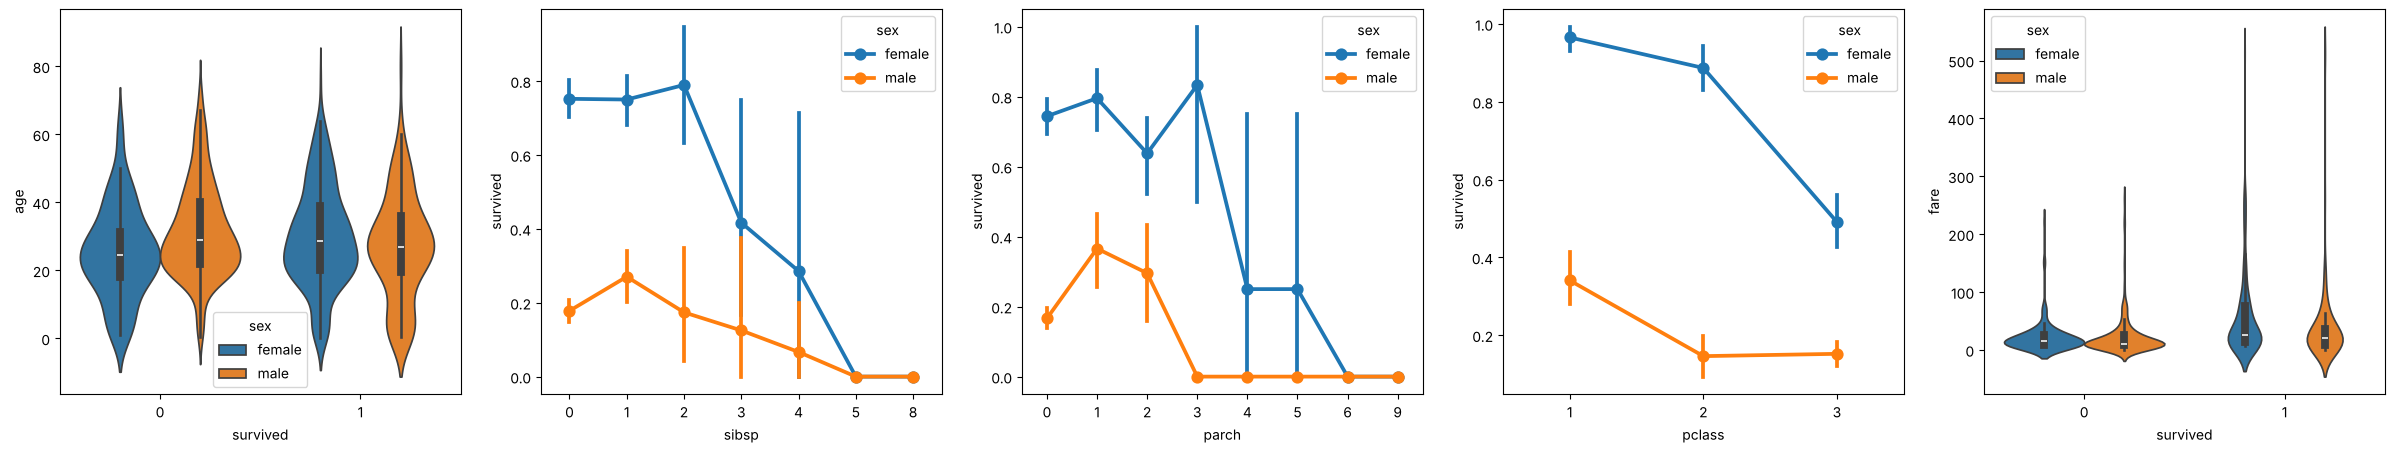

In [2]:
fig, axs = plt.subplots(ncols=5, figsize=(30, 5))
sns.violinplot(x="survived", y="age", hue="sex", data=data, ax=axs[0])
sns.pointplot(x="sibsp", y="survived", hue="sex", data=data, ax=axs[1])
sns.pointplot(x="parch", y="survived", hue="sex", data=data, ax=axs[2])
sns.pointplot(x="pclass", y="survived", hue="sex", data=data, ax=axs[3])
sns.violinplot(x="survived", y="fare", hue="sex", data=data, ax=axs[4])
plt.show()

## 3. Prepare features

`relatives` flags anyone travelling with family. `sex` is encoded as 1 = male, 0 = female.

In [3]:
data['sex'] = data['sex'].map({'male': 1, 'female': 0})
data['relatives'] = ((data['sibsp'] + data['parch']) > 0).astype(int)

data.corr(numeric_only=True).abs()[["survived"]].sort_values("survived", ascending=False)

,survived
survived,1.000000
sex,0.528693
pclass,0.312469
fare,0.244265
relatives,0.201719
parch,0.082660
age,0.055512
sibsp,0.027825
body,NaN


### Title

Every name includes a title ("Allison, **Master**. Hudson Trevor"). It combines sex, age and status in one field: "Master" was used for boys, so it separates children from adult men in a way `sex` alone can't. Uncommon titles (Dr, Rev, Col, Countess…) are grouped as "Rare", and French forms are mapped to their English equivalents.

In [4]:
title = data['name'].str.extract(r',\s*([^.]+)\.')[0]
title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
data['title'] = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

data.groupby('title').agg(passengers=('survived', 'size'),
                          survival_rate=('survived', 'mean'),
                          median_age=('age', 'median')).round(2).sort_values('survival_rate')

,passengers,survival_rate,median_age
title,,,
Mr,757,0.16,29.0
Rare,29,0.38,47.5
Master,61,0.51,4.0
Miss,264,0.68,22.0
Mrs,198,0.79,35.0


Adult men ("Mr") survived at 16%, while boys ("Master", median age 4) survived at 51%: the "women and children first" rule shows up clearly.

About 20% of passengers have no recorded age. The original version dropped them with `dropna()`; here missing values are filled with the median inside the model pipeline, so every passenger is used and the median is learned only from training data in each fold (no leakage from the test fold).

In [5]:
NUMERIC = ['sex', 'pclass', 'age', 'relatives', 'fare']
CATEGORICAL = ['title']
FEATURES = NUMERIC + CATEGORICAL

X = data[FEATURES]
y = data['survived'].astype(int)

X.isna().sum()

sex            0
pclass         0
age          263
relatives      0
fare           1
title          0
dtype: int64

## 4. Compare models with 5-fold cross-validation

The **baseline** always predicts the most common outcome (did not survive). Any useful model has to beat it.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_preprocessor(numeric=NUMERIC, categorical=CATEGORICAL):
    """Median-impute and scale numeric columns; one-hot encode categorical ones."""
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
        (OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
    )

def make_model(estimator, **features):
    return make_pipeline(make_preprocessor(**features), estimator)

candidates = {
    'Baseline (always "died")': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': GaussianNB(),
    'Logistic regression': LogisticRegression(max_iter=1000),
    'Gradient boosting': HistGradientBoostingClassifier(max_depth=3, random_state=RANDOM_STATE),
}

results = {}
for name, estimator in candidates.items():
    results[name] = cross_val_score(make_model(estimator), X, y, cv=cv, scoring='accuracy')

### Neural network

The same Keras network as the original (two hidden layers of 5 units), trained and scored on the same five folds.

In [7]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide TensorFlow startup logs

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input

def build_network(n_inputs):
    network = Sequential([
        Input(shape=(n_inputs,)),
        Dense(5, kernel_initializer='uniform', activation='relu'),
        Dense(5, kernel_initializer='uniform', activation='relu'),
        Dense(1, kernel_initializer='uniform', activation='sigmoid'),
    ])
    network.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return network

nn_scores = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
    tf.keras.utils.set_random_seed(RANDOM_STATE + fold)
    prep = make_preprocessor()
    X_train = prep.fit_transform(X.iloc[train_idx])
    X_test = prep.transform(X.iloc[test_idx])

    network = build_network(X_train.shape[1])
    network.fit(X_train, y.iloc[train_idx], batch_size=32, epochs=50, verbose=0)
    _, accuracy = network.evaluate(X_test, y.iloc[test_idx], verbose=0)
    nn_scores.append(accuracy)

results['Neural network (Keras)'] = np.array(nn_scores)
network.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 275 (1.08 KB)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 184 (740.00 B)

## 5. Results

In [8]:
summary = pd.DataFrame({
    'mean accuracy': {k: v.mean() for k, v in results.items()},
    'std across folds': {k: v.std() for k, v in results.items()},
}).sort_values('mean accuracy', ascending=False)

summary.map(lambda v: f"{v:.1%}")

,mean accuracy,std across folds
Gradient boosting,81.0%,0.9%
Logistic regression,79.8%,2.1%
Neural network (Keras),79.3%,1.8%
Naive Bayes,77.0%,2.0%
"Baseline (always ""died"")",61.8%,0.1%


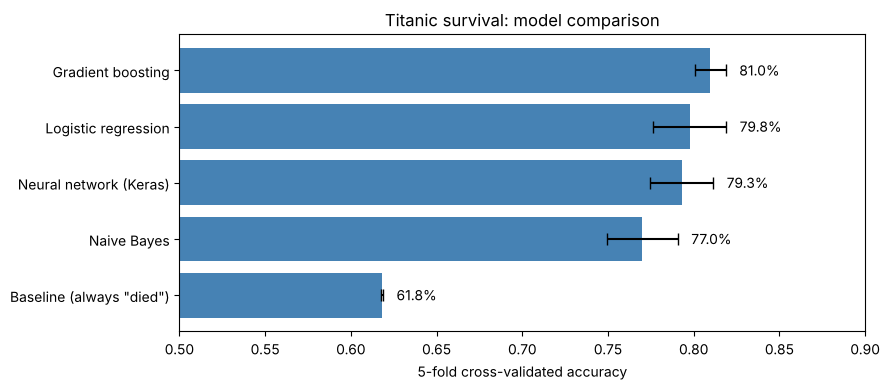

In [9]:
order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(order, summary.loc[order, 'mean accuracy'],
        xerr=summary.loc[order, 'std across folds'], color='steelblue', capsize=4)
ax.set_xlim(0.5, 0.9)
ax.set_xlabel('5-fold cross-validated accuracy')
ax.set_title('Titanic survival: model comparison')
for i, name in enumerate(order):
    mean, spread = summary.loc[name, 'mean accuracy'], summary.loc[name, 'std across folds']
    ax.text(mean + spread + 0.008, i, f'{mean:.1%}', va='center')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120)
plt.show()

### Did the title feature help?

The same two models, scored on the same folds with and without `title`:

In [10]:
without_title = dict(numeric=NUMERIC, categorical=[])
title_effect = {}
for name in ['Logistic regression', 'Gradient boosting']:
    before = cross_val_score(make_model(candidates[name], **without_title), X, y, cv=cv).mean()
    title_effect[name] = {'without title': before, 'with title': results[name].mean()}

title_effect = pd.DataFrame(title_effect).T
title_effect['change'] = title_effect['with title'] - title_effect['without title']
title_effect.map(lambda v: f"{v:+.1%}" if abs(v) < 0.5 else f"{v:.1%}")

,without title,with title,change
Logistic regression,78.6%,79.8%,+1.1%
Gradient boosting,80.1%,81.0%,+0.9%


## 6. Inside the best model

### Who does it get wrong?

Every passenger is predicted once, by the fold model that never saw them during training.

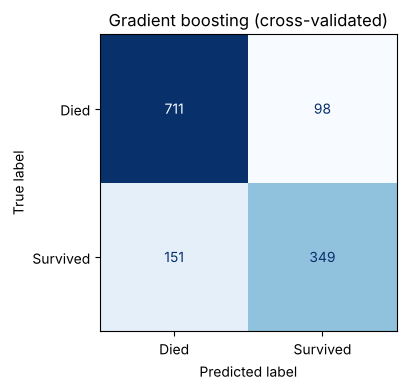

              precision    recall  f1-score   support

        Died      0.825     0.879     0.851       809
    Survived      0.781     0.698     0.737       500

    accuracy                          0.810      1309
   macro avg      0.803     0.788     0.794      1309
weighted avg      0.808     0.810     0.807      1309



In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = make_model(candidates['Gradient boosting'])
predicted = cross_val_predict(best, X, y, cv=cv)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y, predicted, display_labels=['Died', 'Survived'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Gradient boosting (cross-validated)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120)
plt.show()

print(classification_report(y, predicted, target_names=['Died', 'Survived'], digits=3))

In [12]:
# Which groups are hardest? Error rate by sex and class
errors = data.assign(wrong=(predicted != y))
error_table = errors.pivot_table(index='pclass', columns=errors['sex'].map({1: 'male', 0: 'female'}),
                                 values='wrong', aggfunc='mean')
error_table.map(lambda v: f"{v:.0%}")

sex,female,male
pclass,,
1,3%,32%
2,11%,8%
3,43%,14%


### Which features matter?

**Permutation importance:** shuffle one column at a time in the held-out fold and measure how much accuracy drops. A big drop means the model leans on that feature. Averaged over the five folds.

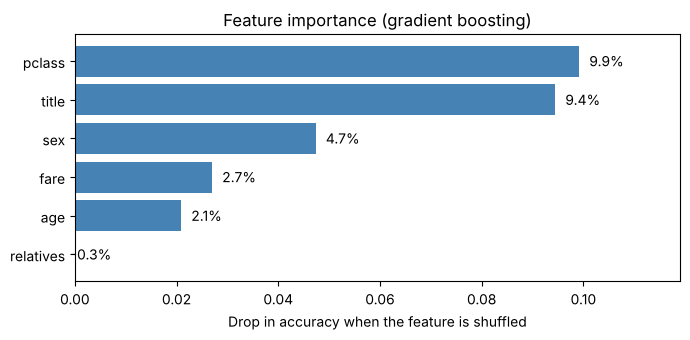

In [13]:
from sklearn.inspection import permutation_importance

drops = []
for train_idx, test_idx in cv.split(X, y):
    fold_model = make_model(candidates['Gradient boosting']).fit(X.iloc[train_idx], y.iloc[train_idx])
    result = permutation_importance(fold_model, X.iloc[test_idx], y.iloc[test_idx],
                                    n_repeats=20, random_state=RANDOM_STATE, scoring='accuracy')
    drops.append(result.importances_mean)

importance = pd.Series(np.mean(drops, axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance.index, importance.values, color='steelblue')
ax.set_xlabel('Drop in accuracy when the feature is shuffled')
ax.set_title('Feature importance (gradient boosting)')
for i, v in enumerate(importance.values):
    ax.text(v + 0.002, i, f'{v:.1%}', va='center')
ax.set_xlim(0, importance.max() * 1.2)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120)
plt.show()

## Takeaways

- Every model clears the ~62% baseline by a wide margin. The top three land within about 2 points of each other (79.3–81.0%), close to the fold-to-fold spread, so gradient boosting's lead is small. The original notebook's big neural-network advantage (79.9% vs 74.6% for Naive Bayes) came from a single 80/20 split.
- Adding **title** improved logistic regression and gradient boosting by about a point each. It mainly helps identify boys ("Master"), who survived far more often than adult men.
- The model leans toward predicting "died": it catches 88% of those who died but only 70% of survivors (151 survivors were missed).
- It is most reliable for first- and second-class women (who mostly survived) and second- and third-class men (who mostly died). Most of its mistakes are on third-class women (43% wrong) and first-class men (32% wrong), whose outcomes were close to a coin flip.
- Passenger class and title matter most. Sex ranks third only because title already carries most of the same information (Mr vs Mrs/Miss); fare and age add a little, and travelling with family adds almost nothing.

**Possible next steps:** tune gradient boosting with a grid search; try family size as a count instead of a yes/no flag.